In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder1 = Path("Oct2023")
folder2 = Path("Nov2023")
files = sorted(folder1.rglob("*.csv"))
files+=sorted(folder2.rglob("*.csv"))

print("Number of CSV files:", len(files))

for f in files:
    print(f)

Number of CSV files: 22
Oct2023/2023-10.csv
Oct2023/2023-10_1.csv
Oct2023/2023-10_2.csv
Oct2023/2023-10_3.csv
Oct2023/2023-10_4.csv
Oct2023/2023-10_5.csv
Oct2023/2023-10_6.csv
Oct2023/2023-10_7.csv
Oct2023/2023-10_8.csv
Oct2023/2023-10_9.csv
Nov2023/2023-11.csv
Nov2023/2023-11_1.csv
Nov2023/2023-11_10.csv
Nov2023/2023-11_11.csv
Nov2023/2023-11_2.csv
Nov2023/2023-11_3.csv
Nov2023/2023-11_4.csv
Nov2023/2023-11_5.csv
Nov2023/2023-11_6.csv
Nov2023/2023-11_7.csv
Nov2023/2023-11_8.csv
Nov2023/2023-11_9.csv


In [13]:

file_info = []

for f in files:
    df = pd.read_csv(f,skiprows=2)

    file_info.append({
        "file": f.name,
        "folder": f.parent.name,
        "rows": len(df),
        "columns": len(df.columns),
        "start_time": df["t_s"].iloc[0],
        "end_time": df["t_s"].iloc[-1],
        "duration_s": df["t_s"].iloc[-1] - df["t_s"].iloc[0],
        "duplicate_rows": df.duplicated().sum(),
        "duplicate_timestamps": df["t_s"].duplicated().sum(),
        "missing_values": df.isna().sum().sum()
    })

file_info = pd.DataFrame(file_info)

file_info


#-----------
#start time no 9 file is -ve

,file,folder,rows,columns,start_time,end_time,duration_s,duplicate_rows,duplicate_timestamps,missing_values
0,2023-10.csv,Oct2023,22866,58,0.000,114.326421,114.326421,0,0,0
1,2023-10_1.csv,Oct2023,23156,58,0.000,115.776579,115.776579,0,0,0
2,2023-10_2.csv,Oct2023,22866,58,0.000,114.326421,114.326421,0,0,0
3,2023-10_3.csv,Oct2023,23156,58,0.000,115.776579,115.776579,0,0,0
4,2023-10_4.csv,Oct2023,23345,58,0.000,116.721536,116.721536,0,0,0
5,2023-10_5.csv,Oct2023,46484,58,0.000,232.417292,232.417292,0,0,0
6,2023-10_6.csv,Oct2023,22115,58,0.000,110.570792,110.570792,0,0,0
7,2023-10_7.csv,Oct2023,26996,58,0.000,134.975816,134.975816,0,0,0
8,2023-10_8.csv,Oct2023,42365,58,0.000,211.822149,211.822149,0,0,0
9,2023-10_9.csv,Oct2023,23844,58,-0.003,119.212134,119.215134,0,0,0


In [15]:
sampling_info = []

for f in files:
    df = pd.read_csv(f,skiprows=2)

    dt = df["t_s"].diff().dropna()

    sampling_info.append({
        "file": f.name,
        "median_dt": dt.median(),
        "mean_dt": dt.mean(),
        "min_dt": dt.min(),
        "max_dt": dt.max(),
        "estimated_frequency_Hz": 1 / dt.median()
    })

sampling_info = pd.DataFrame(sampling_info)

sampling_info


#----------------------------
# we use dt to caluclte sideslip angle

,file,median_dt,mean_dt,min_dt,max_dt,estimated_frequency_Hz
0,2023-10.csv,0.005,0.005,0.004999,0.005001,199.996000
1,2023-10_1.csv,0.005,0.005,0.004999,0.005003,199.996000
2,2023-10_2.csv,0.005,0.005,0.004999,0.005001,199.996000
3,2023-10_3.csv,0.005,0.005,0.004999,0.005003,199.996000
4,2023-10_4.csv,0.005,0.005,0.004999,0.005004,199.996000
5,2023-10_5.csv,0.005,0.005,0.004998,0.005001,200.000000
6,2023-10_6.csv,0.005,0.005,0.004998,0.005002,200.000000
7,2023-10_7.csv,0.005,0.005,0.004999,0.005001,200.000000
8,2023-10_8.csv,0.005,0.005,0.004999,0.005002,199.996000
9,2023-10_9.csv,0.005,0.005,0.005000,0.005000,199.999757


In [32]:
df=pd.read_csv(files[0],skiprows=2)
temp=df.columns.tolist()
for col in temp:
    print(col)

t_s
Ve_mps
Vn_mps
Vu_mps
rollAngle_rad
pitchAngle_rad
yawAngle_rad
rollRate_radps
pitchRate_radps
yawRate_radps
Vx_mps
Vy_mps
Vz_mps
roadWheelAngle_rad
slipAngle_rad
axCG_mps2
ayCG_mps2
azCG_mps2
posE_m
posN_m
posU_m
posRMSerror_m
brake_fl_bar
brake_fr_bar
brake_rl_bar
brake_rr_bar
brakeCmd_fl_bar
brakeCmd_fr_bar
brakeCmd_rl_bar
brakeCmd_rr_bar
brake_fl_N
brake_fr_N
brake_rl_N
brake_rr_N
wheelspeed_fl
wheelspeed_fr
wheelspeed_rl
wheelspeed_rr
ABSactive_bool
LSDengage_percent
GearRatio
engineTorque_Nm
engine_rpm
throttleCmd_percent
clutchEngage_int
tireTemp_fl_degC
tireTemp_rl_degC
tireTemp_fr_degC
tireTemp_rr_degC
suspFLpos_m
suspFRpos_m
suspRLpos_m
auto_steer_bool
auto_throttle_bool
s_m
grade_rad
bank_rad
vertical_curvature_radpm


In [34]:
#Take 21 features relevant ----
#velocity in body frame -2
#accn-2
#ts-1
#yaw,rooll,pitchrate-3
#steeringangle-1
#throttle brake -5
#engine wheel-6
#LSD-1



OUTPUT = Path("phaseclass")
OUTPUT.mkdir(exist_ok=True)


phase_features = [
    "t_s",
    "Vx_mps",
    "Vy_mps",
    "yawRate_radps",
    "roadWheelAngle_rad",
    "ayCG_mps2",
    "axCG_mps2",
    "throttleCmd_percent",
    "brake_fl_bar",
    "brake_fr_bar",
    "brake_rl_bar",
    "brake_rr_bar",
    "engineTorque_Nm",
    "engine_rpm",
    "wheelspeed_fl",
    "wheelspeed_fr",
    "wheelspeed_rl",
    "wheelspeed_rr",
    "LSDengage_percent",
    
    "rollRate_radps",
    "pitchRate_radps"
]

for f in files:
    df = pd.read_csv(f, skiprows=2)
    phaseclass = df[phase_features].copy()
    phaseclass.to_csv(
        OUTPUT / f"{f.stem}_phaseclass.csv",
        index=False
    )


print("Phase-class files created:", len(list(OUTPUT.glob("*.csv"))))

Phase-class files created: 22


In [35]:

#---------------t_s Stats------------------
from pathlib import Path
import pandas as pd
import numpy as np

files = sorted(Path("phaseclass").glob("*.csv"))

print("Number of files:", len(files))
all_stats = []

for f in files:
    df = pd.read_csv(f)

    stats = df.describe().T
    stats["file"] = f.name

    all_stats.append(stats)

all_stats = pd.concat(all_stats)

all_stats
info = []

for f in files:
    df = pd.read_csv(f)

    dt = df["t_s"].diff().dropna()

    info.append({
        "file": f.name,
        "rows": len(df),
        "duration_s": df["t_s"].iloc[-1] - df["t_s"].iloc[0],
        "median_dt": dt.median(),
        "frequency_Hz": 1 / dt.median(),
        "missing_values": df.isna().sum().sum(),
        "duplicate_rows": df.duplicated().sum(),
        "duplicate_time": df["t_s"].duplicated().sum()
    })

info = pd.DataFrame(info)

info

Number of files: 22


,file,rows,duration_s,median_dt,frequency_Hz,missing_values,duplicate_rows,duplicate_time
0,2023-10_1_phaseclass.csv,23156,115.776579,0.005,199.996000,0,0,0
1,2023-10_2_phaseclass.csv,22866,114.326421,0.005,199.996000,0,0,0
2,2023-10_3_phaseclass.csv,23156,115.776579,0.005,199.996000,0,0,0
3,2023-10_4_phaseclass.csv,23345,116.721536,0.005,199.996000,0,0,0
4,2023-10_5_phaseclass.csv,46484,232.417292,0.005,200.000000,0,0,0
5,2023-10_6_phaseclass.csv,22115,110.570792,0.005,200.000000,0,0,0
6,2023-10_7_phaseclass.csv,26996,134.975816,0.005,200.000000,0,0,0
7,2023-10_8_phaseclass.csv,42365,211.822149,0.005,199.996000,0,0,0
8,2023-10_9_phaseclass.csv,23844,119.215134,0.005,199.999757,0,0,0
9,2023-10_phaseclass.csv,22866,114.326421,0.005,199.996000,0,0,0


In [38]:
important = [
    "Vx_mps",
    "Vy_mps",
    "yawRate_radps",
    "roadWheelAngle_rad",
    "ayCG_mps2",
    "axCG_mps2",
    "throttleCmd_percent",
    "engineTorque_Nm",
    "engine_rpm",
    "LSDengage_percent"
]

for f in files:
    df = pd.read_csv(f)

    print("\n" + "=" * 80)
    print(f.name)

    print(
        df[important]
        .describe()
        .T[["mean", "std", "min", "max"]]
    )


2023-10_1_phaseclass.csv
                            mean          std         min          max
Vx_mps                 22.681628     7.511838    3.053575    32.000795
Vy_mps                 -0.303177     0.586945   -2.197148     1.668651
yawRate_radps           0.054393     0.264716   -0.735307     0.794474
roadWheelAngle_rad      0.016033     0.067702   -0.183754     0.254668
ayCG_mps2               1.109281     6.936000  -23.694579    25.589307
axCG_mps2               0.196734     1.826991   -5.389367     5.036563
throttleCmd_percent    41.965027    39.039600    0.000000   100.000000
engineTorque_Nm        97.900069   125.769139  -68.000000   364.000000
engine_rpm           3912.517058  1195.325232  949.000000  6424.000000
LSDengage_percent       0.998808     3.424285    0.000000    38.800000

2023-10_2_phaseclass.csv
                            mean          std         min          max
Vx_mps                 22.442928     8.219969   -0.053170    32.048943
Vy_mps                 -0

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INPUT = Path("phaseclass")

files = sorted(INPUT.glob("*.csv"))

speed_results = []

for file in files:

    df = pd.read_csv(file)

    df["speed_mps"] = np.sqrt(
        df["Vx_mps"]**2 +
        df["Vy_mps"]**2
    )

    speed_results.append({
        "file": file.stem,
        "min_speed": df["speed_mps"].min(),
        "p01_speed": df["speed_mps"].quantile(0.01),
        "p05_speed": df["speed_mps"].quantile(0.05),
        "p10_speed": df["speed_mps"].quantile(0.10),
        "median_speed": df["speed_mps"].median(),
        "max_speed": df["speed_mps"].max()
    })

speed_summary = pd.DataFrame(speed_results)

speed_summary.round(3)

,file,min_speed,p01_speed,p05_speed,p10_speed,median_speed,max_speed
0,2023-10_1_phaseclass,3.055,3.194,5.109,13.317,23.783,32.002
1,2023-10_2_phaseclass,0.000,0.022,3.076,12.297,23.972,32.051
2,2023-10_3_phaseclass,3.055,3.194,5.109,13.317,23.783,32.002
3,2023-10_4_phaseclass,0.000,0.000,0.010,0.050,23.839,32.106
4,2023-10_5_phaseclass,0.000,0.059,10.808,11.820,21.763,32.016
5,2023-10_6_phaseclass,0.233,0.323,6.381,12.162,24.562,32.019
6,2023-10_7_phaseclass,0.000,0.010,0.839,13.282,22.851,31.856
7,2023-10_8_phaseclass,0.000,0.010,12.559,14.804,25.291,32.075
8,2023-10_9_phaseclass,0.000,0.010,1.795,6.130,23.698,31.984
9,2023-10_phaseclass,0.000,0.022,3.076,12.297,23.972,32.051


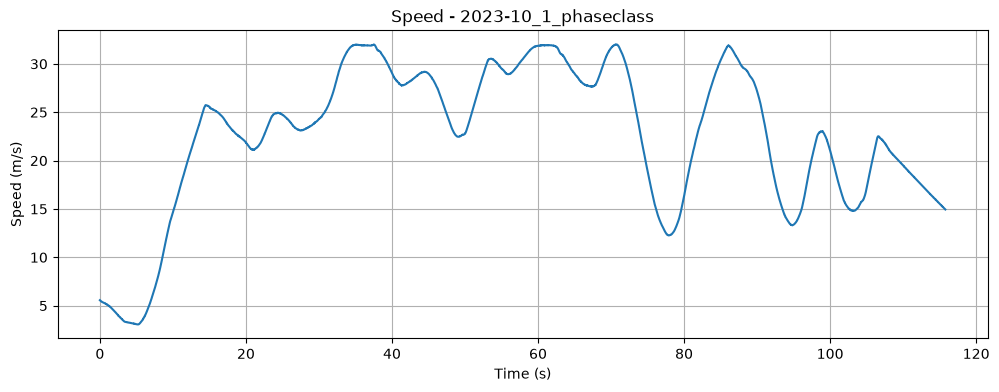

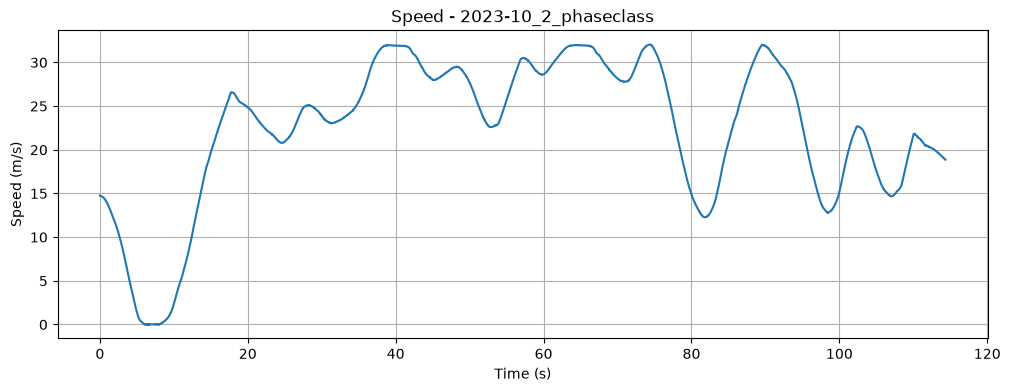

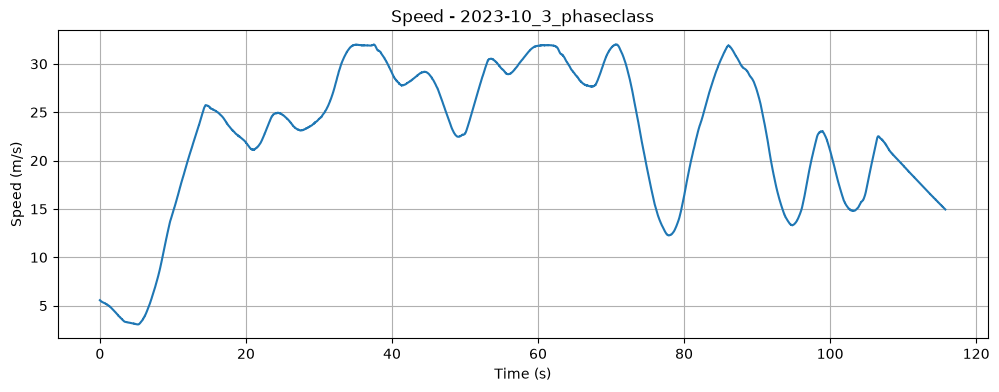

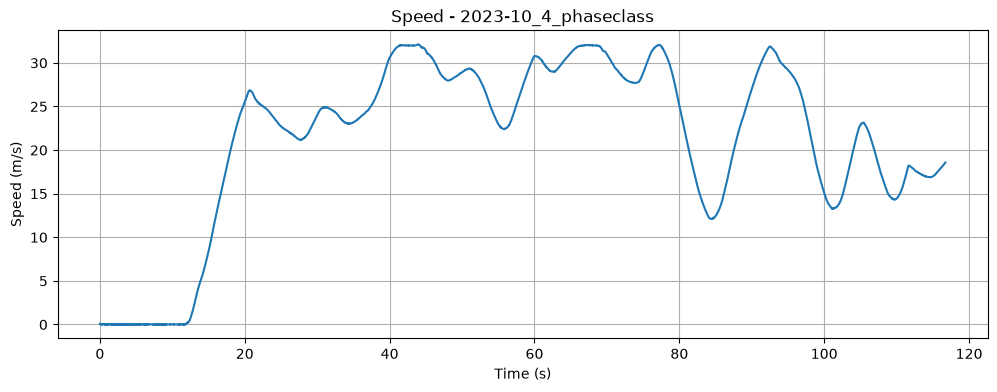

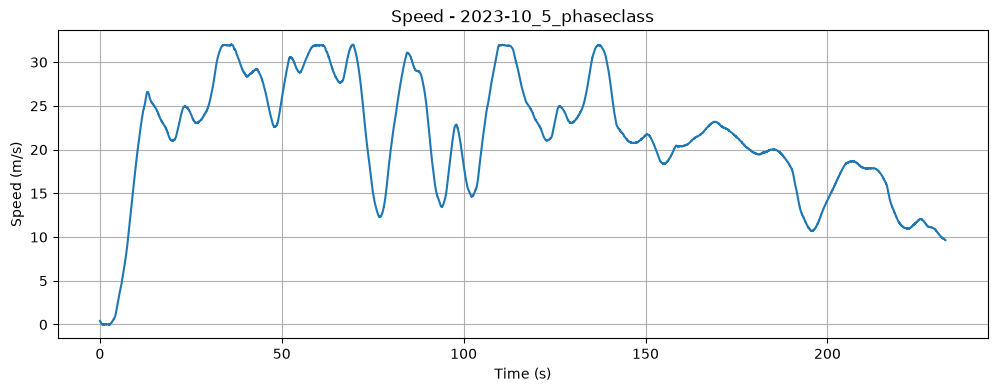

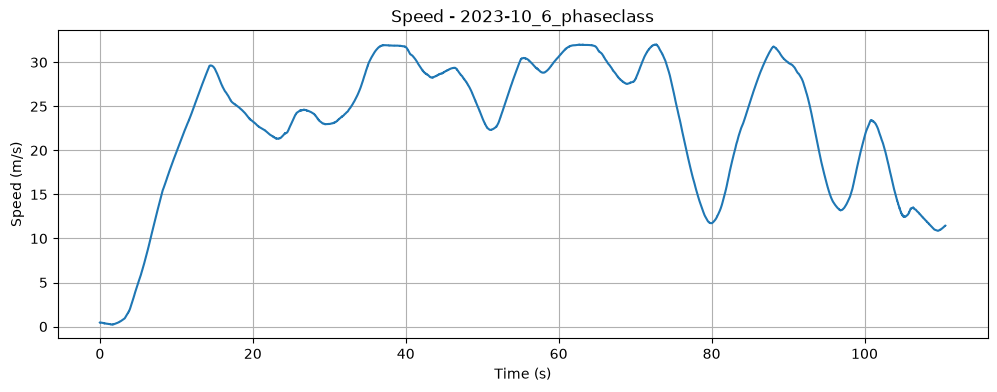

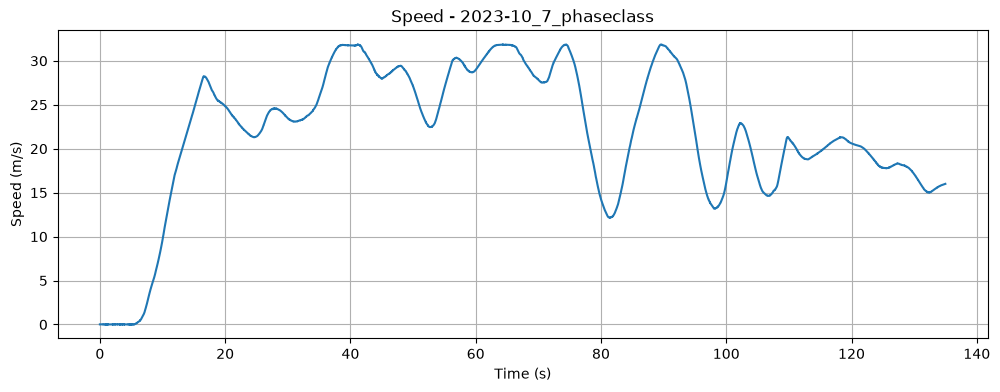

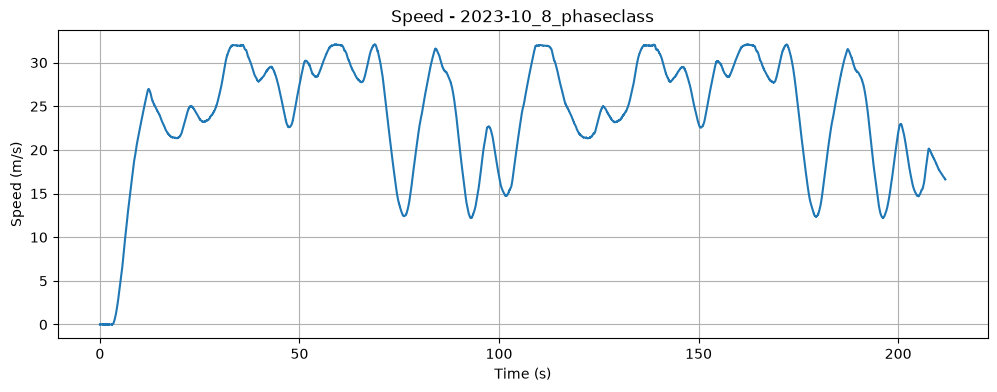

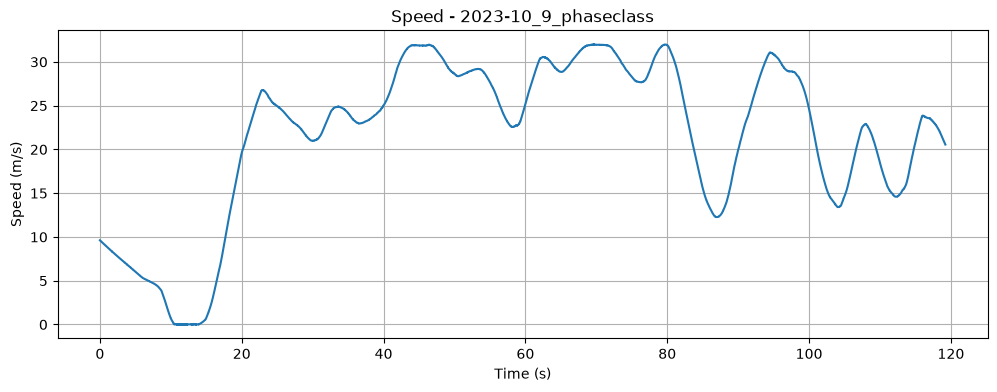

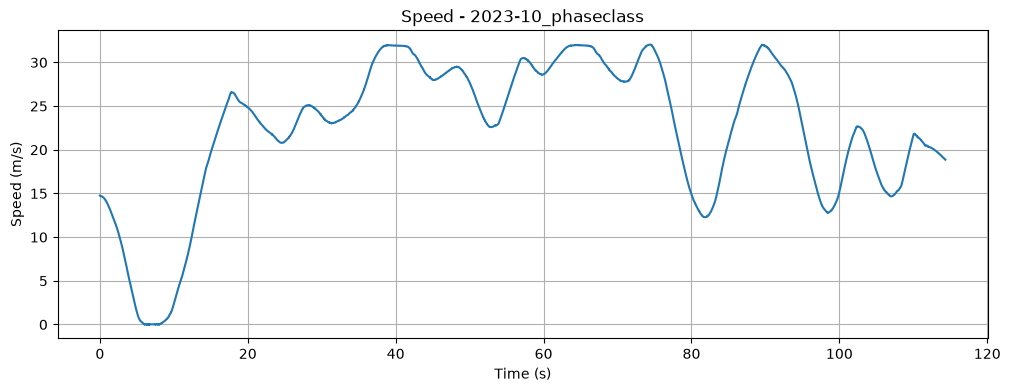

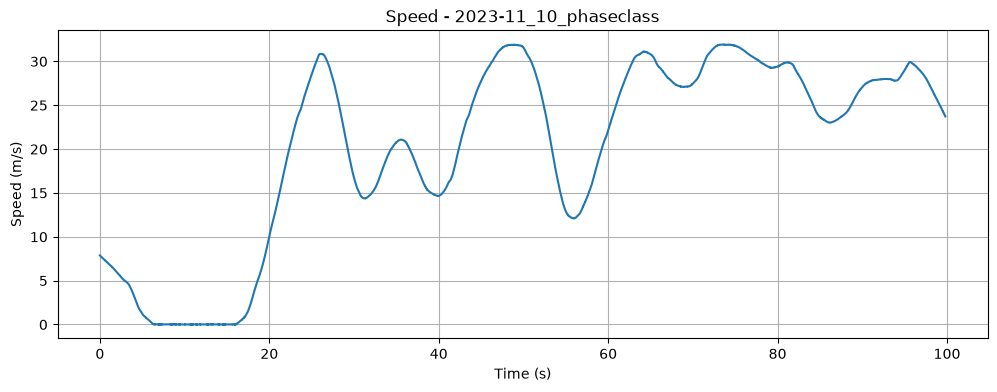

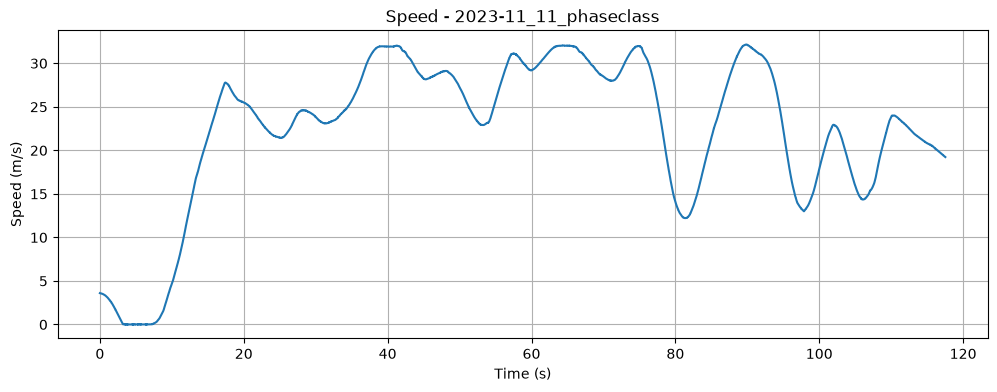

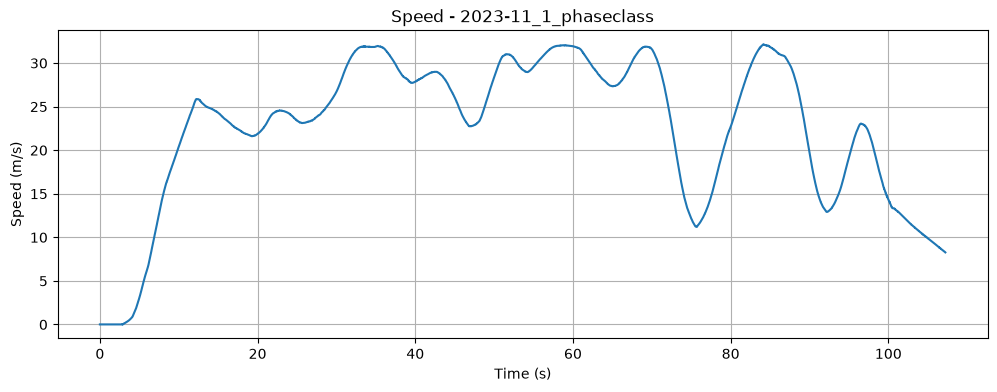

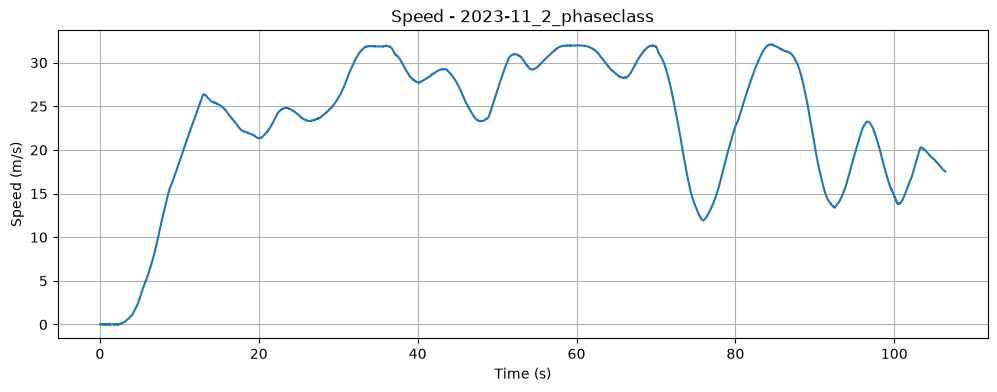

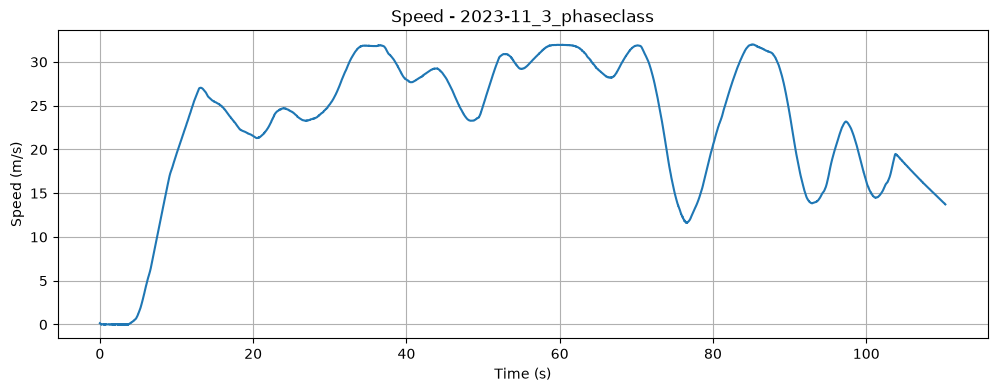

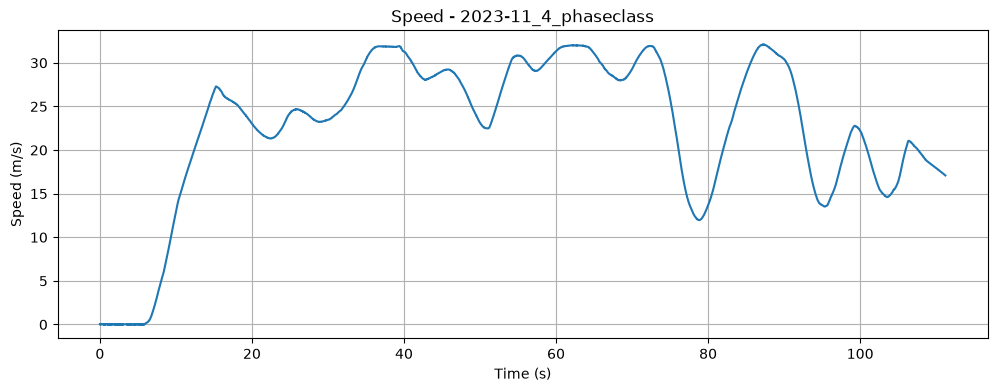

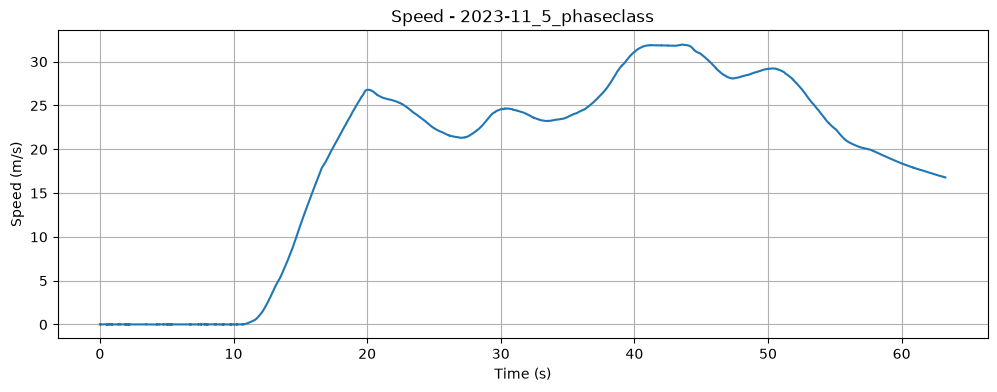

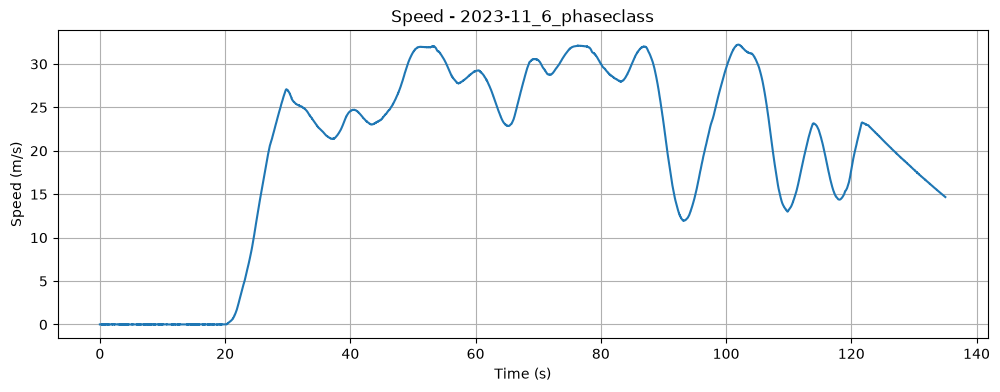

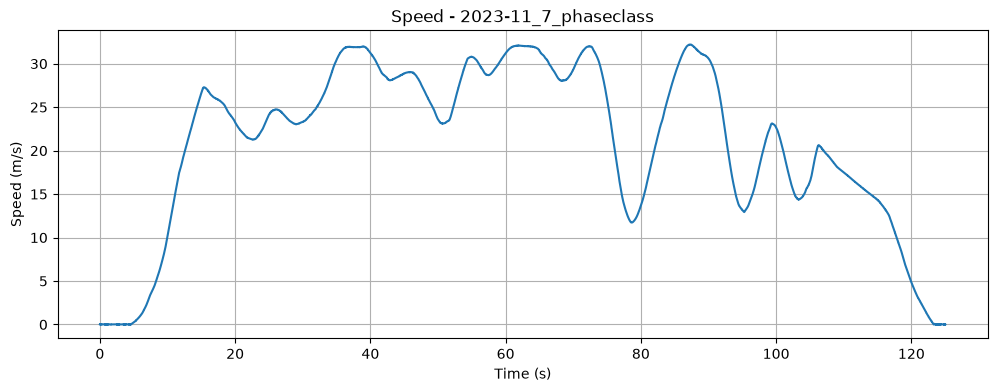

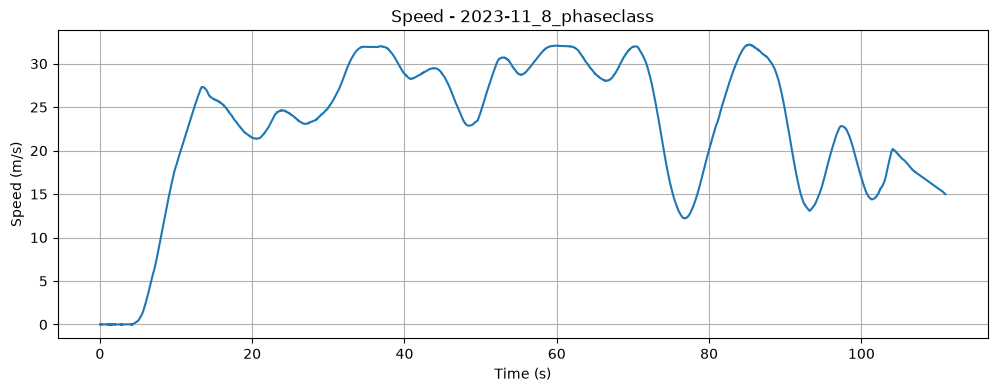

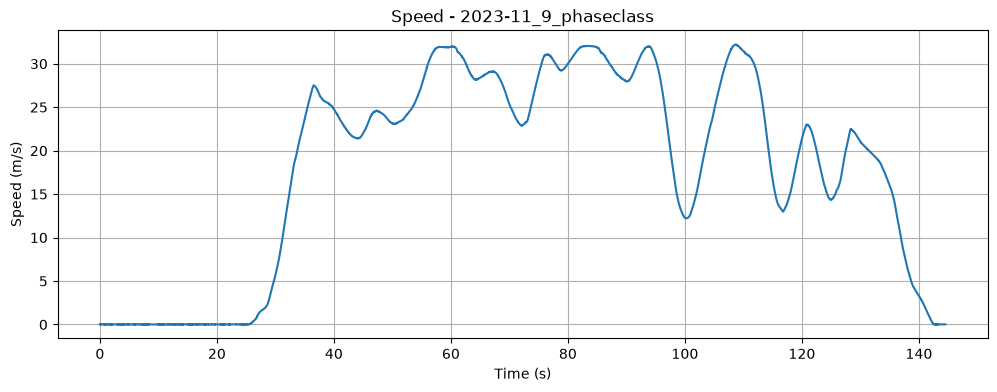

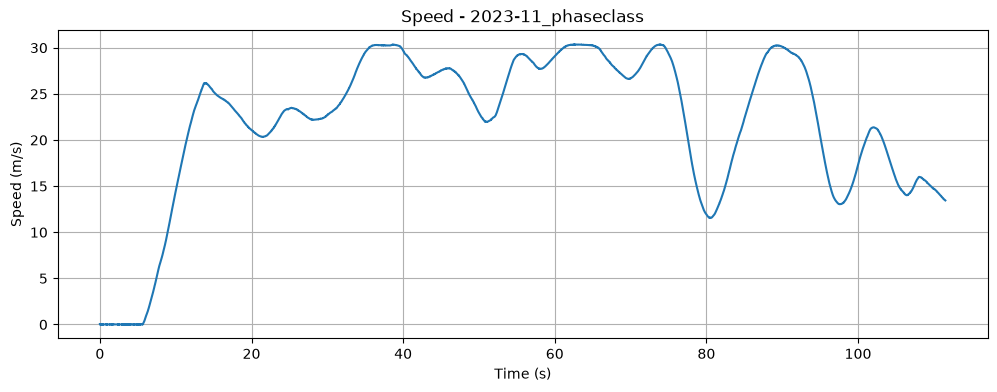

In [62]:
for file in files:

    df = pd.read_csv(file)

    speed = np.sqrt(
        df["Vx_mps"]**2 +
        df["Vy_mps"]**2
    )

    plt.figure(figsize=(12, 4))

    plt.plot(df["t_s"], speed)

    plt.xlabel("Time (s)")
    plt.ylabel("Speed (m/s)")
    plt.title(f"Speed - {file.stem}")

    plt.grid()
    plt.show()

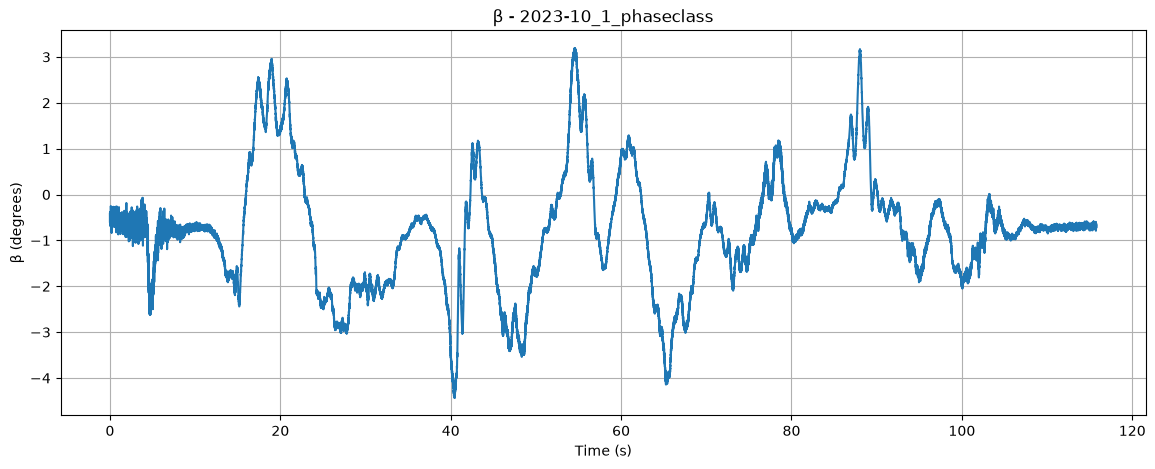

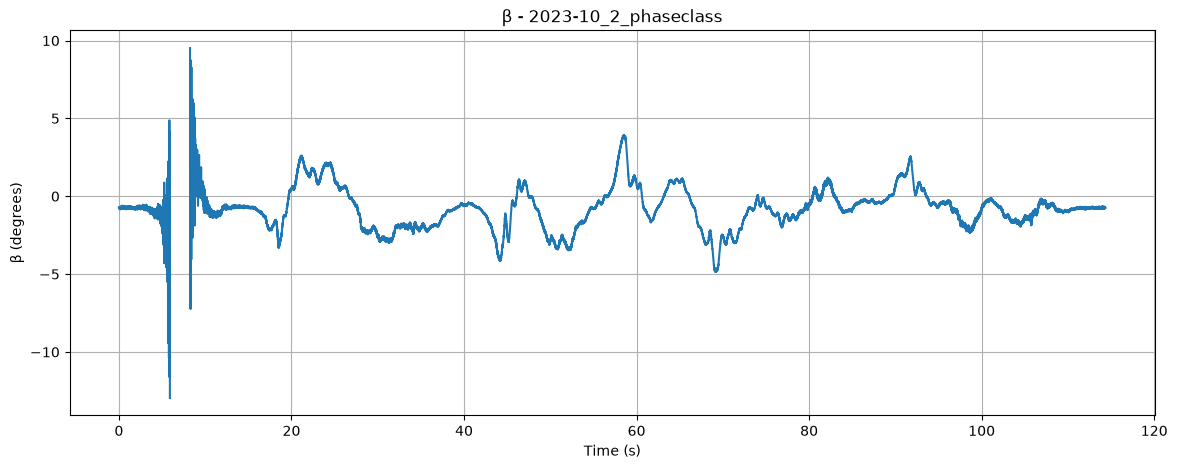

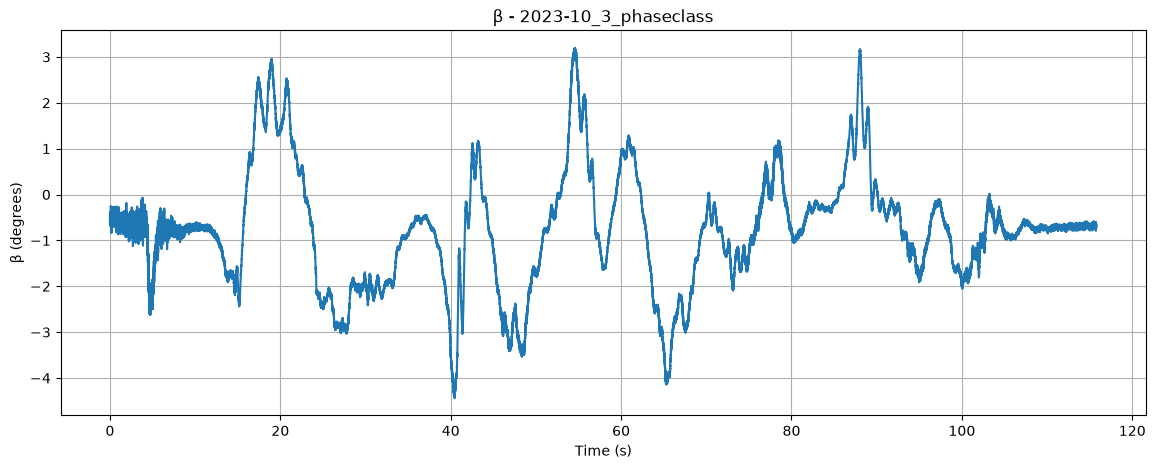

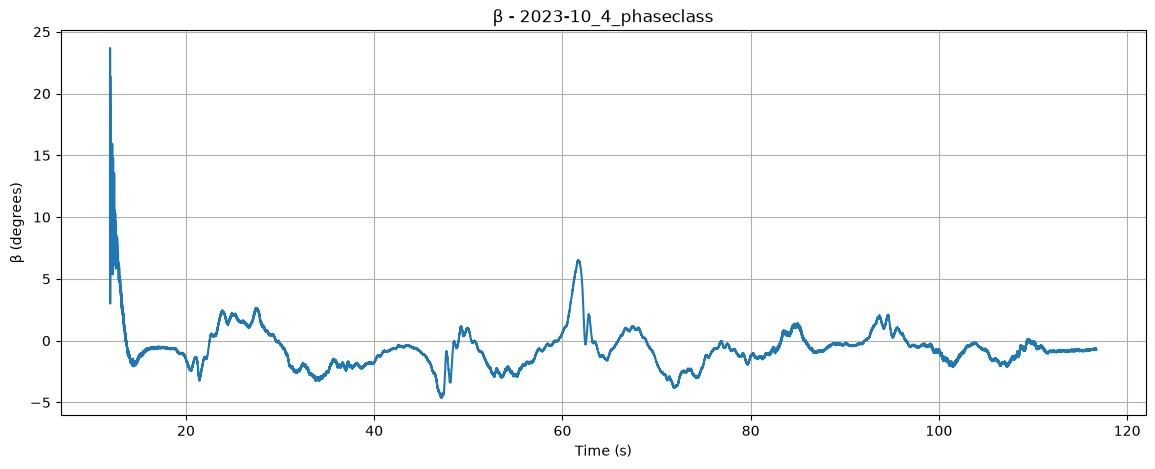

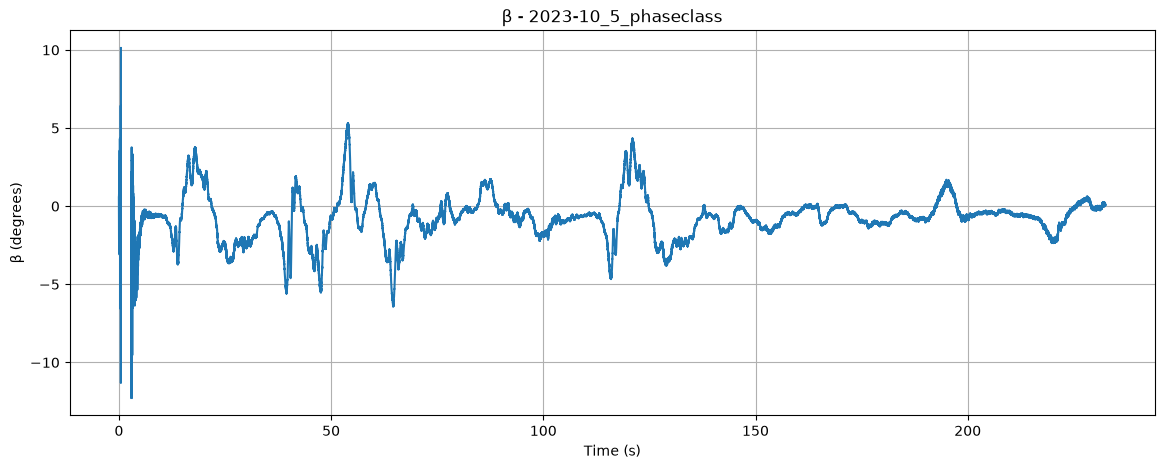

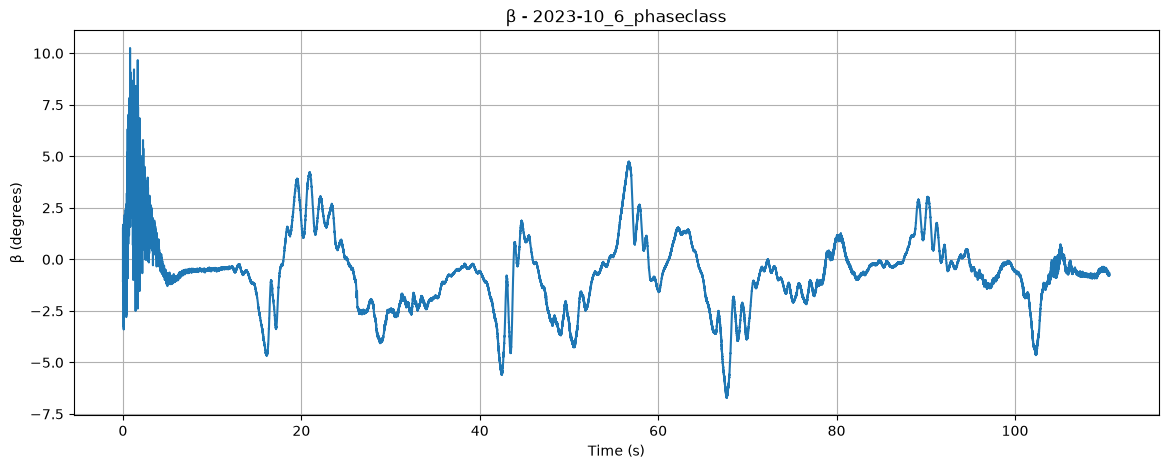

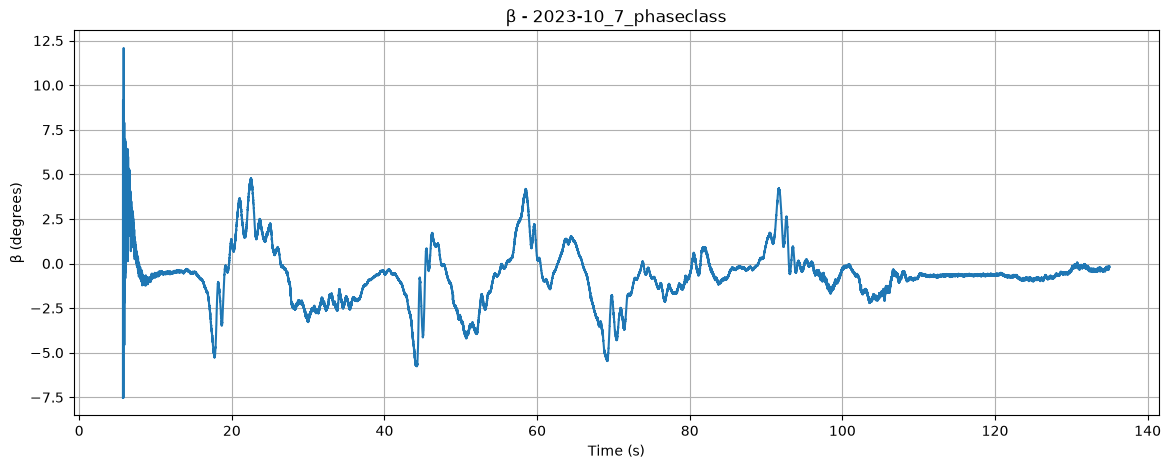

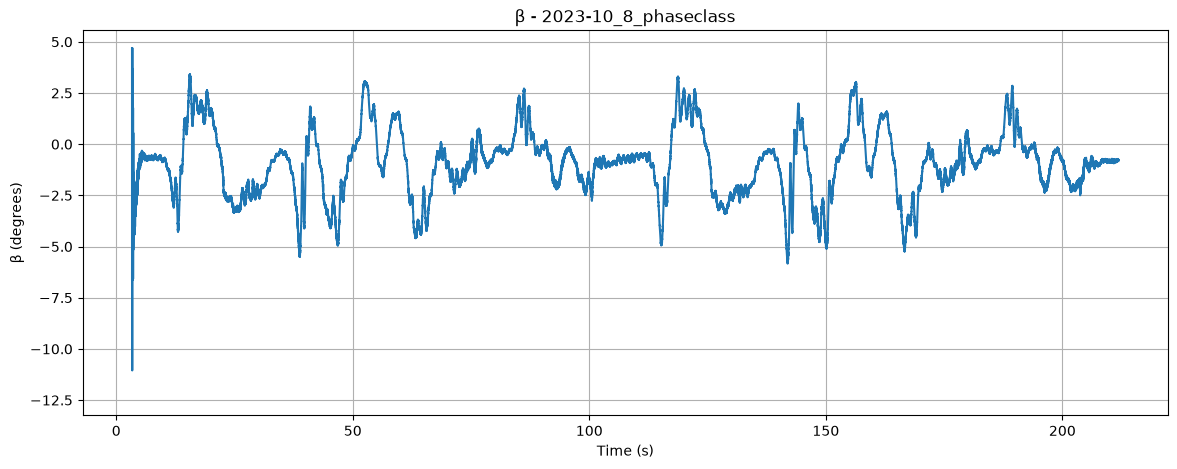

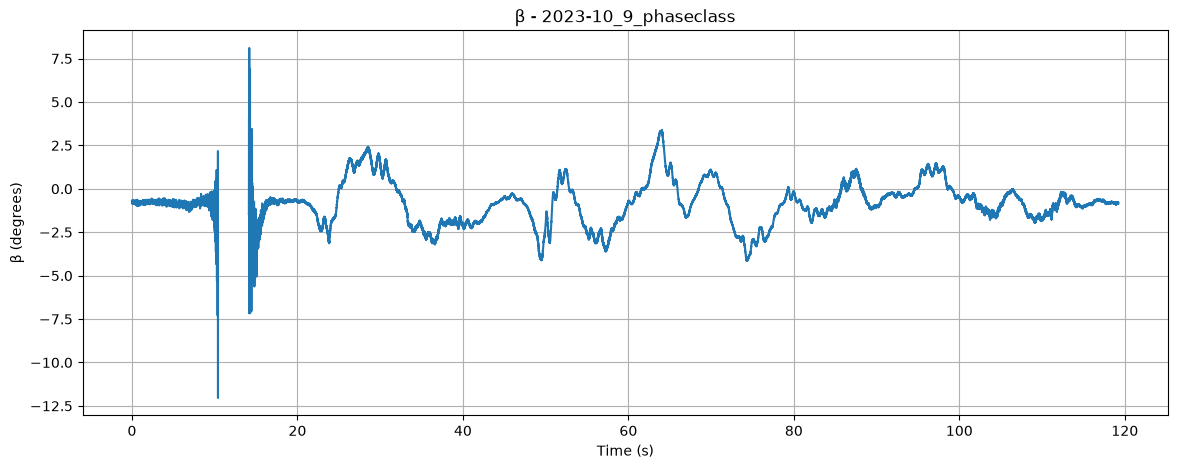

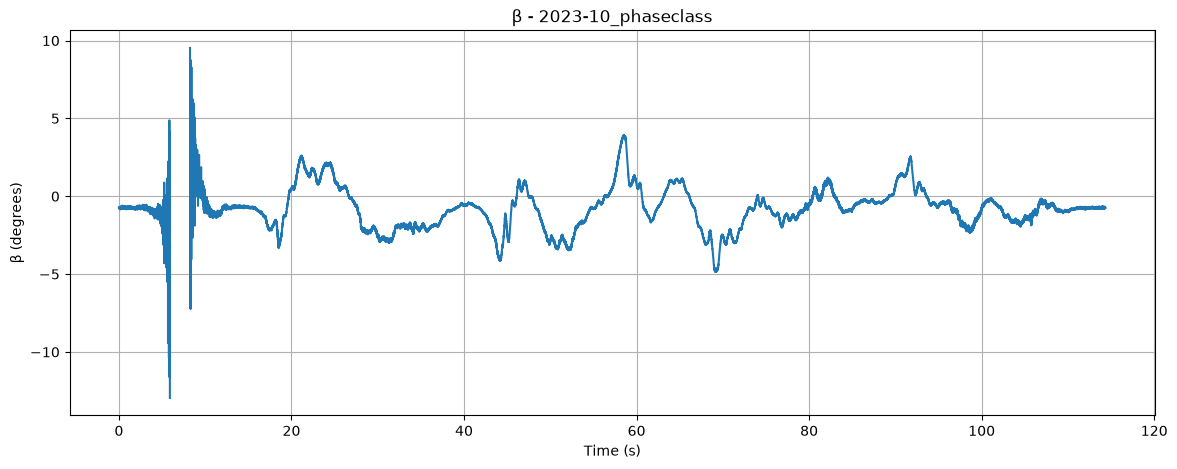

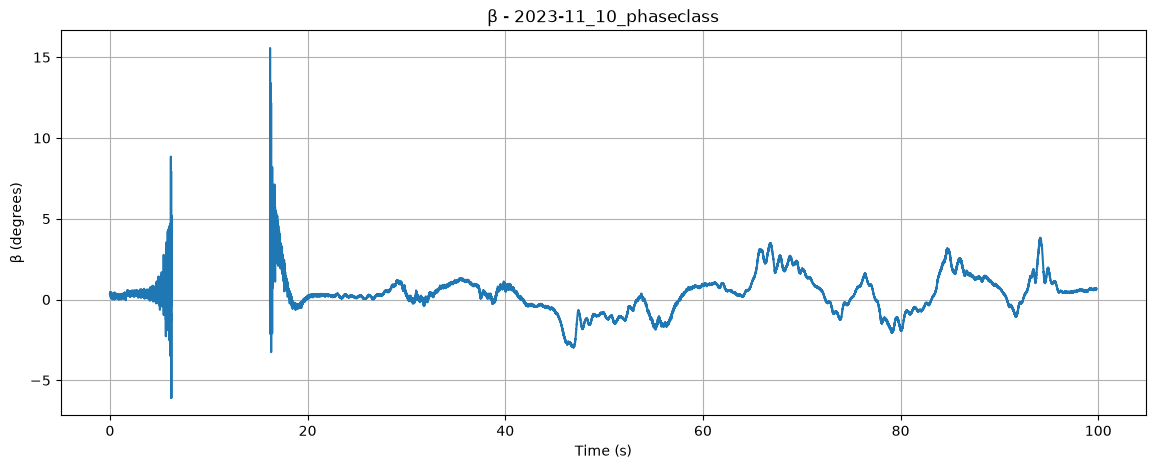

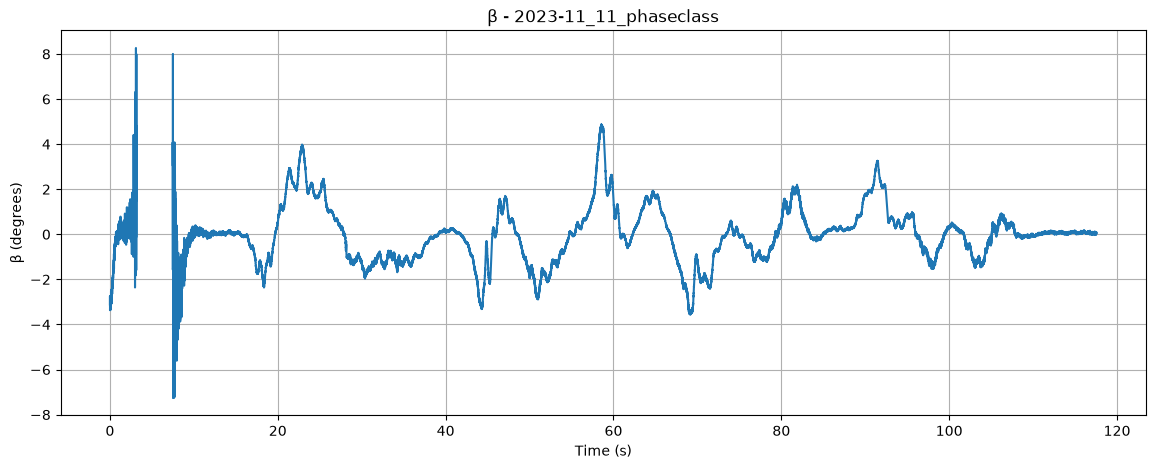

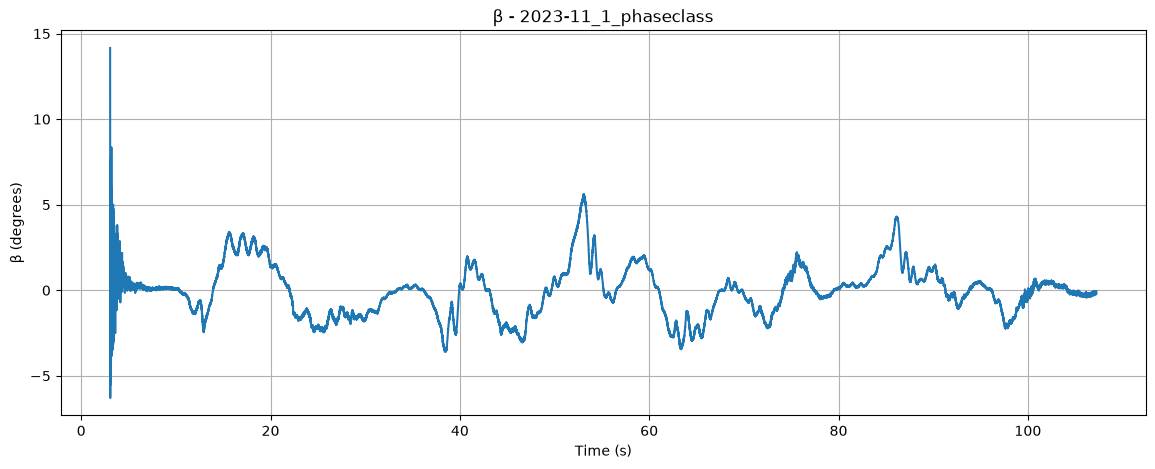

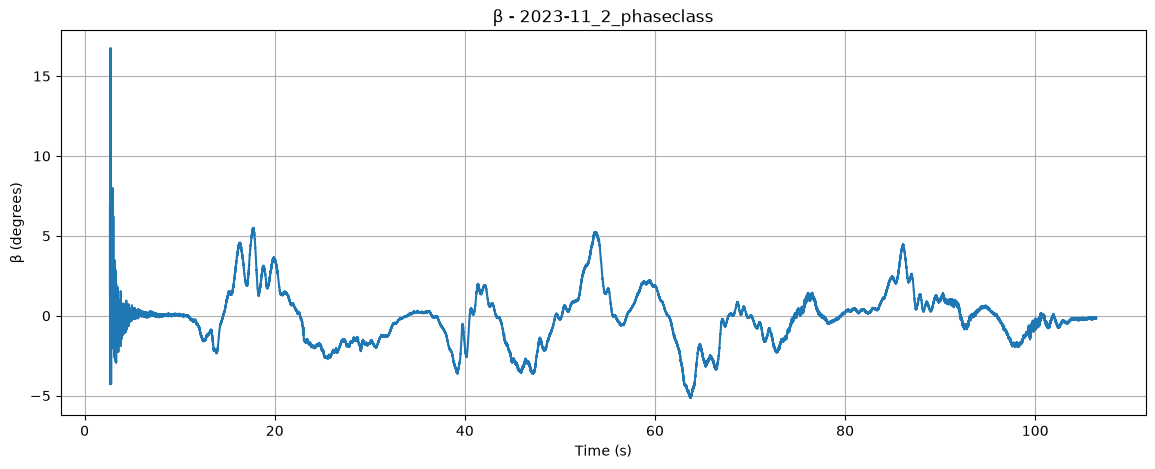

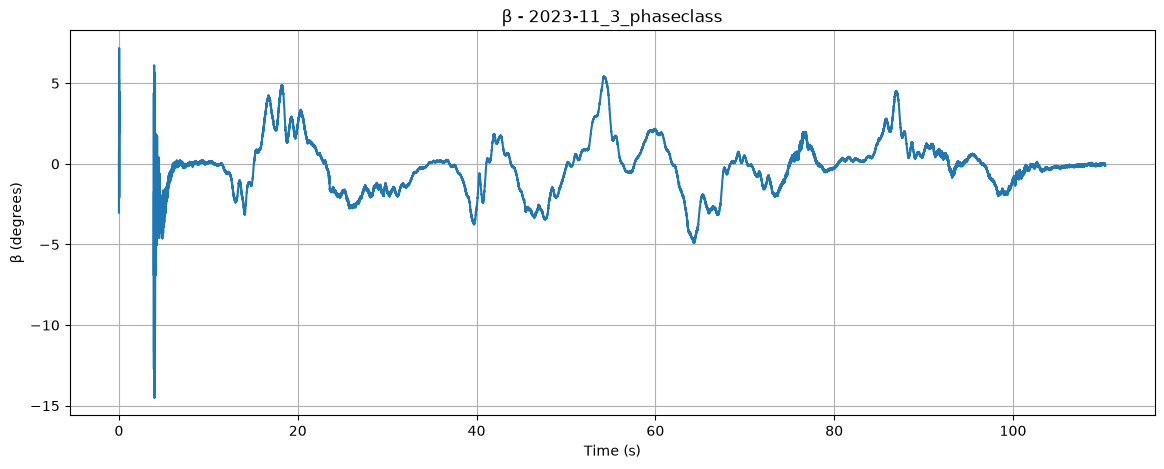

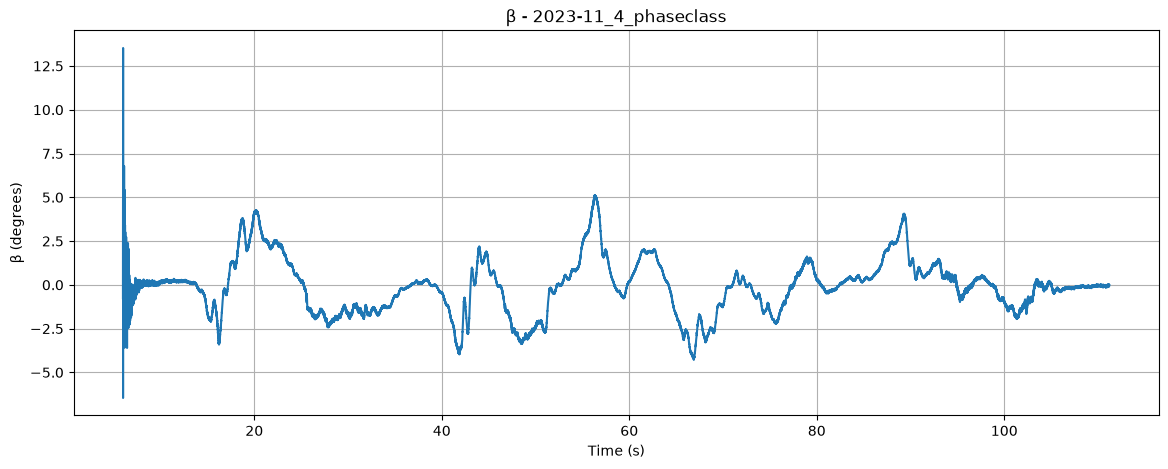

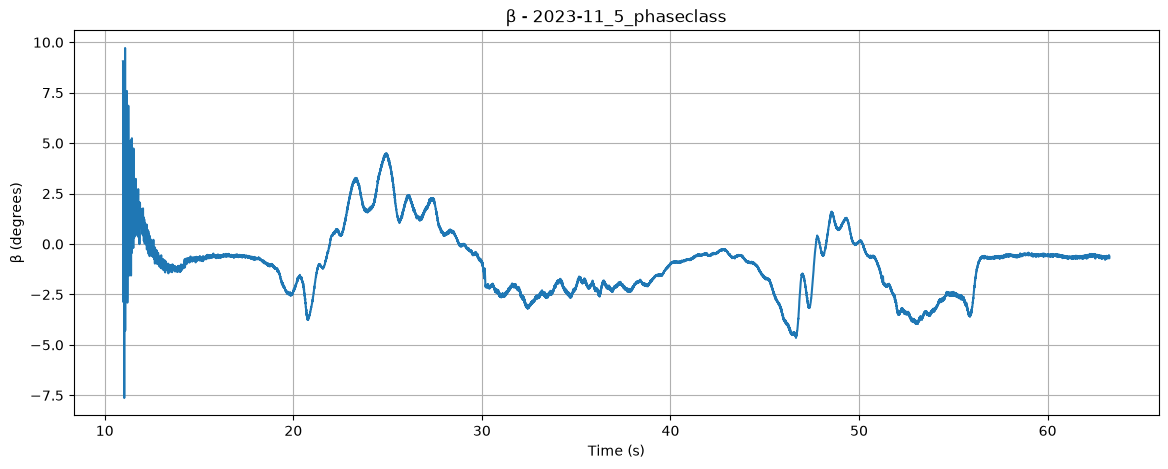

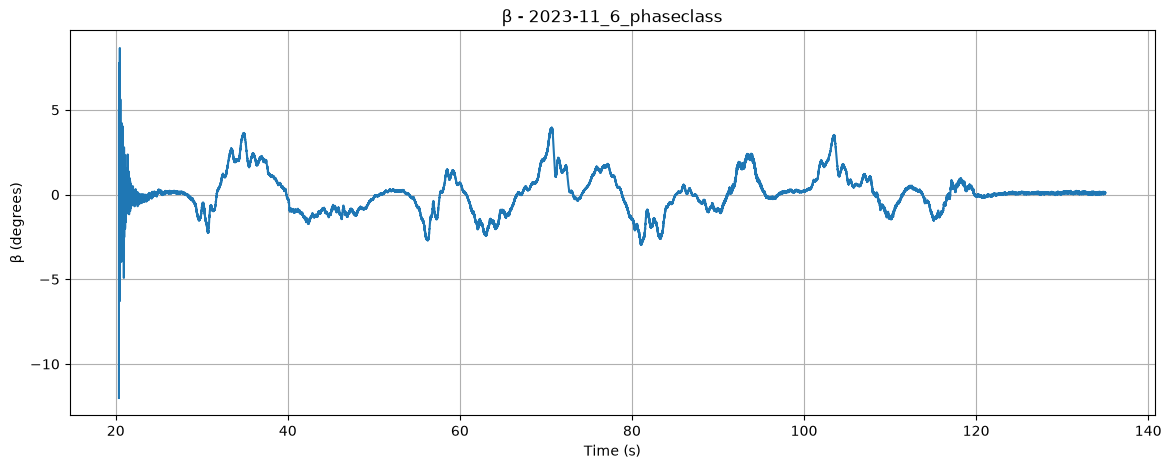

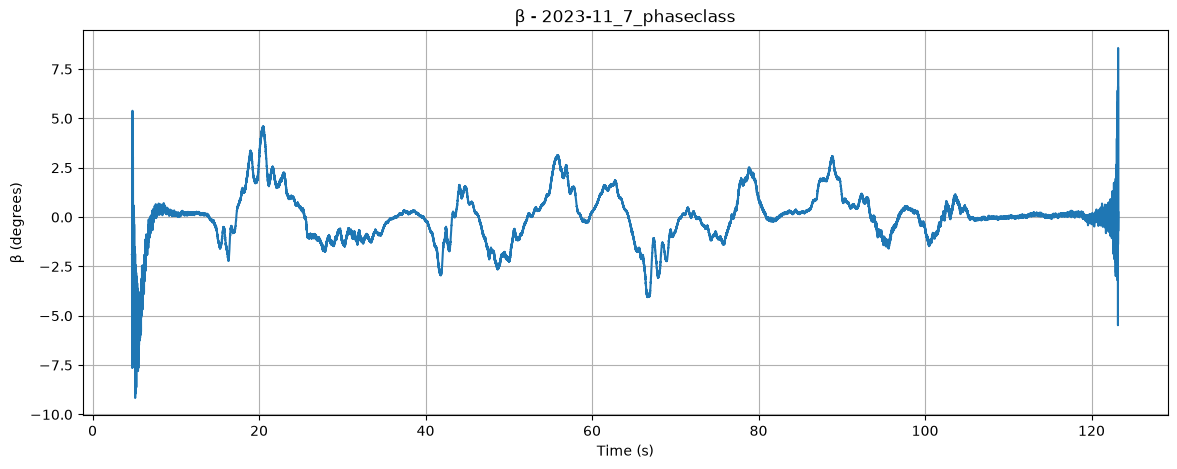

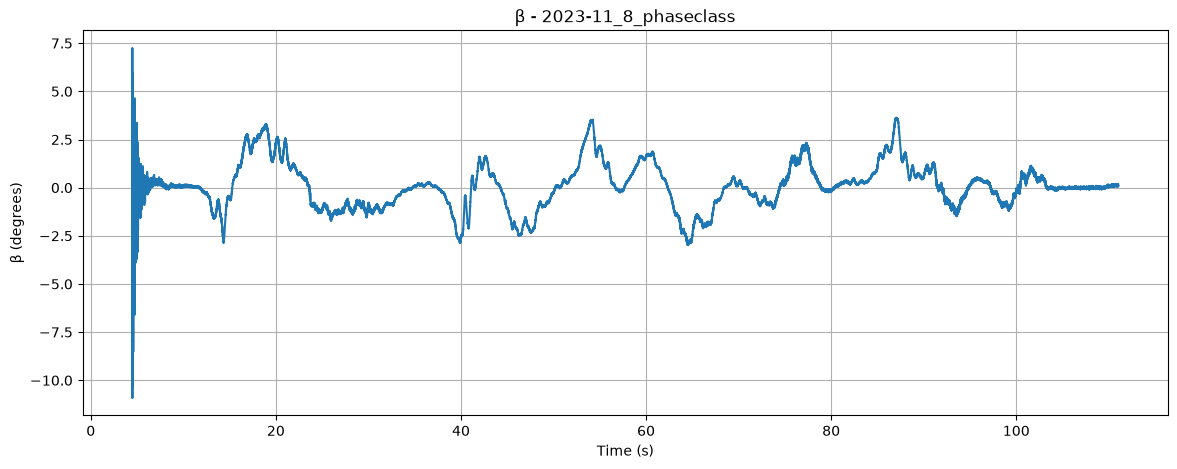

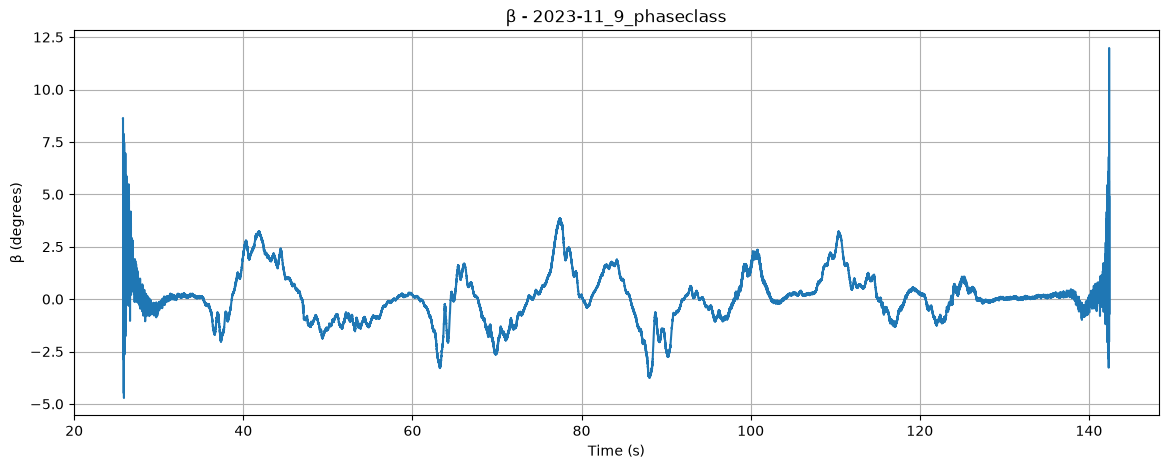

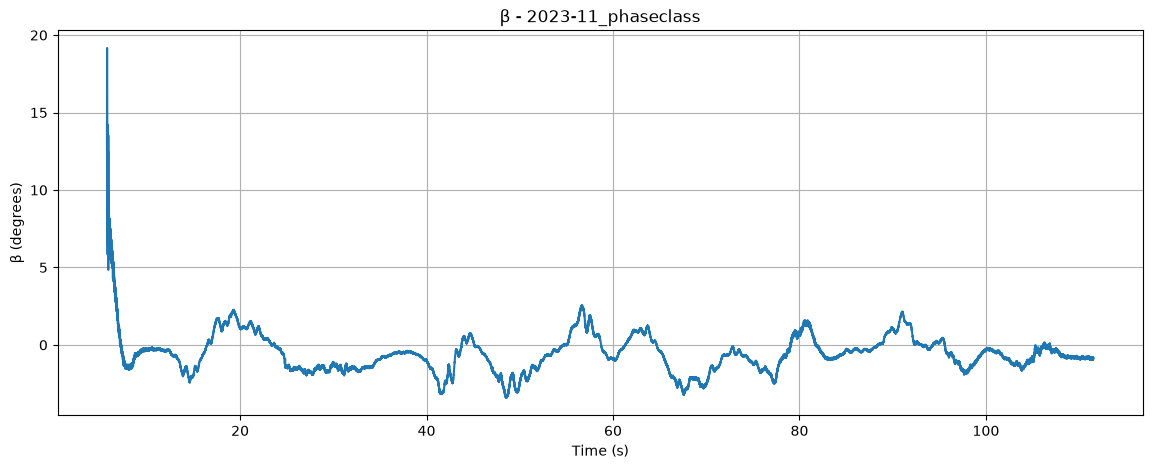

In [63]:
for file in files:

    df = pd.read_csv(file)

    df["speed_mps"] = np.sqrt(
        df["Vx_mps"]**2 +
        df["Vy_mps"]**2
    )

    valid = df["speed_mps"] > 0.1

    beta_rad = np.full(len(df), np.nan)

    beta_rad[valid] = np.arctan2(
        df.loc[valid, "Vy_mps"],
        df.loc[valid, "Vx_mps"]
    )

    df["beta_deg"] = np.degrees(beta_rad)

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["t_s"],
        df["beta_deg"]
    )

    plt.xlabel("Time (s)")
    plt.ylabel("β (degrees)")
    plt.title(f"β - {file.stem}")

    plt.grid()
    plt.show()

In [64]:
import pandas as pd
import numpy as np
from pathlib import Path

INPUT = Path("phaseclass")

files = sorted(INPUT.glob("*.csv"))

for file in files:

    df = pd.read_csv(file)

    df["speed_mps"] = np.sqrt(
        df["Vx_mps"]**2 +
        df["Vy_mps"]**2
    )

    valid = df["speed_mps"] > 0.1

    df["beta_deg"] = np.nan

    df.loc[valid, "beta_deg"] = np.degrees(
        np.arctan2(
            df.loc[valid, "Vy_mps"],
            df.loc[valid, "Vx_mps"]
        )
    )

    df.to_csv(file, index=False)

print("Updated files:", len(files))

Updated files: 22


In [77]:
#--------------Verificvation of 2023_10_2
df = pd.read_csv(files[1])


df[
    df["speed_mps"] >0.1
][
    [
        "t_s",
        "Vx_mps",
        "Vy_mps",
        "speed_mps",
        "beta_deg"
    ]
]

t_s          0
Vx_mps       0
Vy_mps       0
speed_mps    0
beta_deg     0
dtype: int64